In [2]:
import pandas as pd
import scipy.stats as sc
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

oczekiwana 0


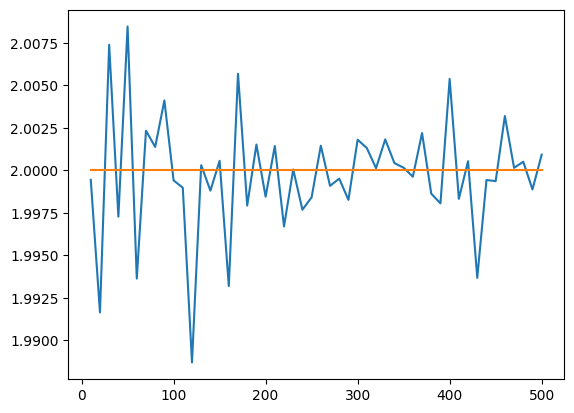

wariancja 0


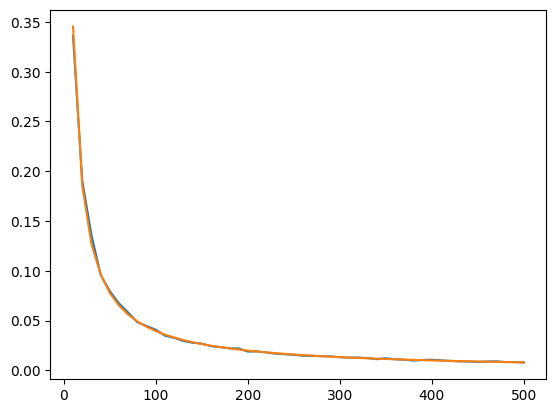

MSE 0


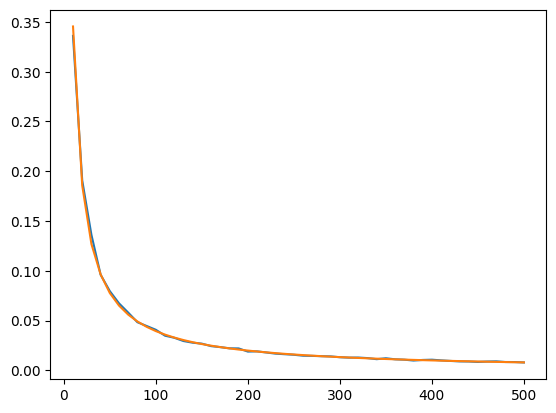

bias 0


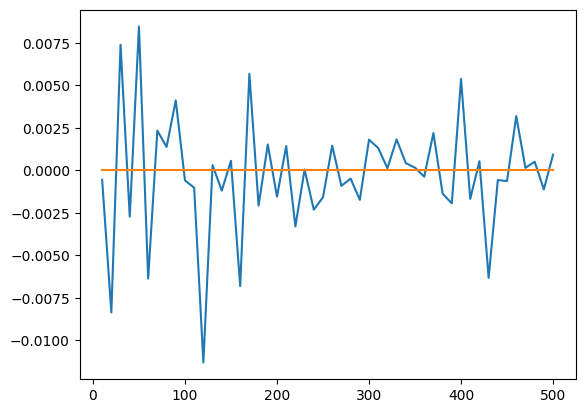

oczekiwana 1


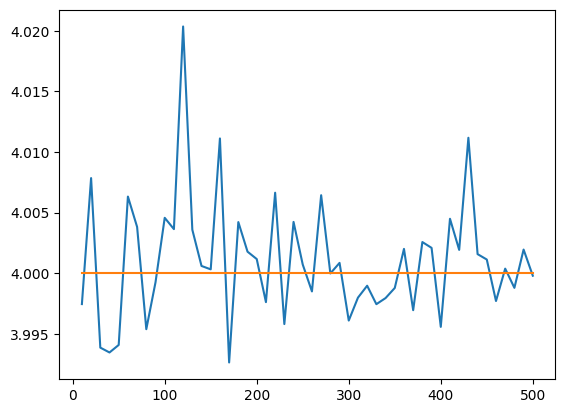

wariancja 1


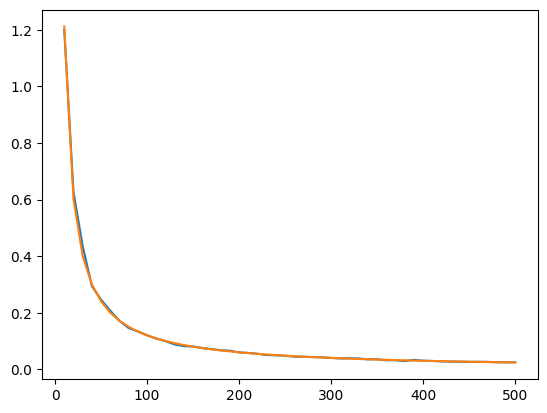

MSE 1


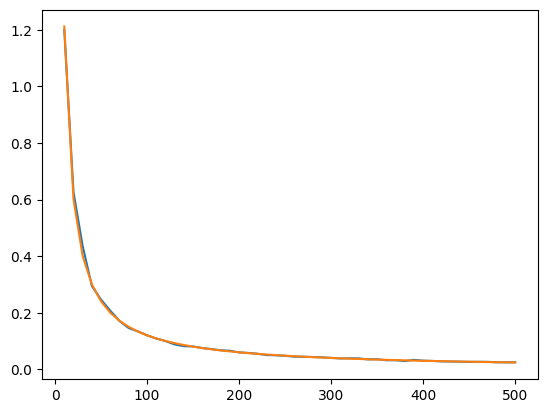

bias 1


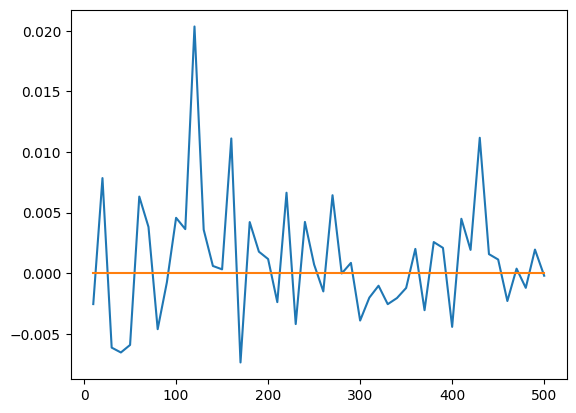

In [10]:
#1
def estymatory_MNK_wspolczynnikow(kolumna_x,kolumna_y):
    y_srednie = np.mean(kolumna_y)
    x_srednie = np.mean(kolumna_x)
    y_odjac_srednie = kolumna_y - y_srednie
    x_odjac_srednie = kolumna_x - x_srednie
    x_odjac_srednie_kwadrat = x_odjac_srednie ** 2
    x_razy_y_odjac_srednie = x_odjac_srednie * y_odjac_srednie

    b_1 = np.sum(x_razy_y_odjac_srednie) / np.sum(x_odjac_srednie_kwadrat)
    b_0 = y_srednie - b_1 * x_srednie

    return b_0,b_1

def xi(n):
    wektor = np.arange(n)/n
    return wektor

def eps(n):
    return np.random.normal(0,1,n)

def model_regresji(xi,eps):
    return 2 + 4 * xi + eps



def monte_carlo(n,m):
    wektor_estymatorow_b0 = []
    wektor_estymatorow_b1 = []

    wektor_x = xi(n)

    for _ in range(m):
        wektor_eps = eps(n)
        wektor_y = model_regresji(wektor_x,wektor_eps)

        b0_daszek, b1_daszek = estymatory_MNK_wspolczynnikow(wektor_x, wektor_y)

        wektor_estymatorow_b0.append(b0_daszek)
        wektor_estymatorow_b1.append(b1_daszek)

    wektor_estymatorow_b0 = np.array(wektor_estymatorow_b0)
    wektor_estymatorow_b1 = np.array(wektor_estymatorow_b1)

    oczekiwana_0 = np.mean(wektor_estymatorow_b0)
    oczekiwana_1 = np.mean(wektor_estymatorow_b1)

    wariancja_0 = np.var(wektor_estymatorow_b0)
    wariancja_1 = np.var(wektor_estymatorow_b1)

    MSE_0 = np.sum((wektor_estymatorow_b0 - 2) ** 2)/m
    MSE_1 = np.sum((wektor_estymatorow_b1 - 4) ** 2)/m

    bias_0 = oczekiwana_0 - 2
    bias_1 = oczekiwana_1 - 4



    teoretyczna_oczekiwana_0 = 2
    teoretyczna_oczekiwana_1 = 4

    suma_kwadratow = np.sum((np.mean(wektor_x) - wektor_x)**2)
    teoretyczna_wariancja_0 = 1/n + np.mean(wektor_x)**2/suma_kwadratow
    teoretyczna_wariancja_1 = 1/suma_kwadratow

    teoretyczne_MSE_0 = teoretyczna_wariancja_0.copy()
    teoretyczne_MSE_1 = teoretyczna_wariancja_1.copy()

    teoretyczny_bias_0 = 0
    teoretyczny_bias_1 = 0


    return  (
            (teoretyczna_oczekiwana_0,teoretyczna_wariancja_0,teoretyczne_MSE_0,teoretyczny_bias_0),
            (oczekiwana_0,wariancja_0,MSE_0,bias_0), 
            (teoretyczna_oczekiwana_1,teoretyczna_wariancja_1,teoretyczne_MSE_1,teoretyczny_bias_1),
            (oczekiwana_1,wariancja_1,MSE_1,bias_1)
            )


wektor_n = []

wektor_teoretyczna_oczekiwana_0 = []
wektor_oczekiwana_0 = []

wektor_teoretyczna_wariancja_0 = []
wektor_wariancja_0 = []

wektor_teoretyczna_MSE_0 = []
wektor_MSE_0 = []

wektor_teoretyczny_bias_0 = []
wektor_bias_0 = []

wektor_teoretyczna_oczekiwana_1 = []
wektor_oczekiwana_1 = []

wektor_teoretyczna_wariancja_1 = []
wektor_wariancja_1 = []

wektor_teoretyczna_MSE_1 = []
wektor_MSE_1 = []

wektor_teoretyczny_bias_1 = []
wektor_bias_1 = []


for i in range(1,51):
    n = i * 10

    wektor_n.append(n)

    teoretyczne_wlasnosci_0, empiryczne_wlasnosci_0, teoretyczne_wlasnosci_1, empiryczne_wlasnosci_1  = monte_carlo(n,2000)

    wektor_teoretyczna_oczekiwana_0.append(teoretyczne_wlasnosci_0[0])
    wektor_teoretyczna_wariancja_0.append(teoretyczne_wlasnosci_0[1])
    wektor_teoretyczna_MSE_0.append(teoretyczne_wlasnosci_0[2])
    wektor_teoretyczny_bias_0.append(teoretyczne_wlasnosci_0[3])

    wektor_oczekiwana_0.append(empiryczne_wlasnosci_0[0])
    wektor_wariancja_0.append(empiryczne_wlasnosci_0[1])
    wektor_MSE_0.append(empiryczne_wlasnosci_0[2])
    wektor_bias_0.append(empiryczne_wlasnosci_0[3])

    wektor_teoretyczna_oczekiwana_1.append(teoretyczne_wlasnosci_1[0])
    wektor_teoretyczna_wariancja_1.append(teoretyczne_wlasnosci_1[1])
    wektor_teoretyczna_MSE_1.append(teoretyczne_wlasnosci_1[2])
    wektor_teoretyczny_bias_1.append(teoretyczne_wlasnosci_1[3])
    
    wektor_oczekiwana_1.append(empiryczne_wlasnosci_1[0])
    wektor_wariancja_1.append(empiryczne_wlasnosci_1[1])
    wektor_MSE_1.append(empiryczne_wlasnosci_1[2])
    wektor_bias_1.append(empiryczne_wlasnosci_1[3])
    

print('oczekiwana 0')
plt.plot(wektor_n,wektor_oczekiwana_0)
plt.plot(wektor_n,wektor_teoretyczna_oczekiwana_0)
plt.show()

print('wariancja 0')
plt.plot(wektor_n,wektor_wariancja_0)
plt.plot(wektor_n,wektor_teoretyczna_wariancja_0)
plt.show()

print('MSE 0')
plt.plot(wektor_n,wektor_MSE_0)
plt.plot(wektor_n,wektor_teoretyczna_MSE_0)
plt.show()

print('bias 0')
plt.plot(wektor_n,wektor_bias_0)
plt.plot(wektor_n,wektor_teoretyczny_bias_0)
plt.show()



print('oczekiwana 1')
plt.plot(wektor_n,wektor_oczekiwana_1)
plt.plot(wektor_n,wektor_teoretyczna_oczekiwana_1)
plt.show()

print('wariancja 1')
plt.plot(wektor_n,wektor_wariancja_1)
plt.plot(wektor_n,wektor_teoretyczna_wariancja_1)
plt.show()

print('MSE 1')
plt.plot(wektor_n,wektor_MSE_1)
plt.plot(wektor_n,wektor_teoretyczna_MSE_1)
plt.show()

print('bias 1')
plt.plot(wektor_n,wektor_bias_1)
plt.plot(wektor_n,wektor_teoretyczny_bias_1)
plt.show()



DLA N = 20
norm
Wariancja b0 = 0.5567321376906735, Obciazenie b0 = 0.004399702155215124
Wariancja b1 = 1.8501556332550442, Obciazenie b1 = -0.0037728361035727076
t3
Wariancja b0 = 0.5449889134423989, Obciazenie b0 = 0.00332537347937345
Wariancja b1 = 1.7940810787912866, Obciazenie b1 = -0.01848901509048151
t10
Wariancja b0 = 0.563027805753059, Obciazenie b0 = 0.0038029106371815224
Wariancja b1 = 1.801713908713735, Obciazenie b1 = -0.02009191384892528


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


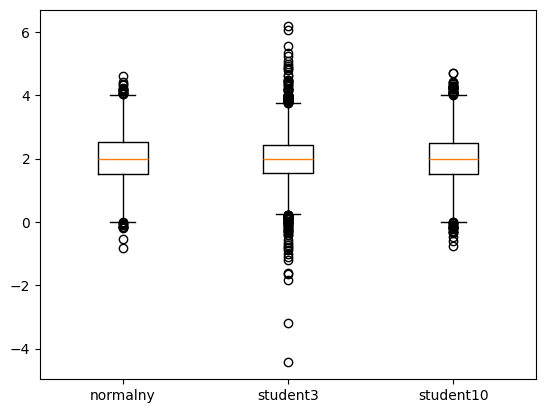

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


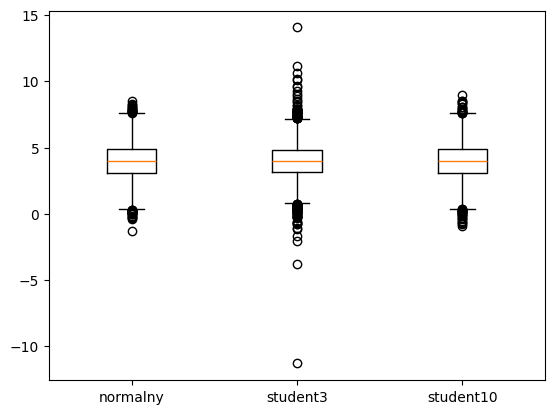

DLA N = 50
norm
Wariancja b0 = 0.23781198380418328, Obciazenie b0 = -0.009677157165244088
Wariancja b1 = 0.7340151883980331, Obciazenie b1 = 0.010230559325947297
t3
Wariancja b0 = 0.217516785613129, Obciazenie b0 = -0.001517331281845058
Wariancja b1 = 0.6759833414278553, Obciazenie b1 = 0.0039028037278345806
t10
Wariancja b0 = 0.2296291483216241, Obciazenie b0 = 0.004008271038354216
Wariancja b1 = 0.7166336972901072, Obciazenie b1 = -0.007705191638967435


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


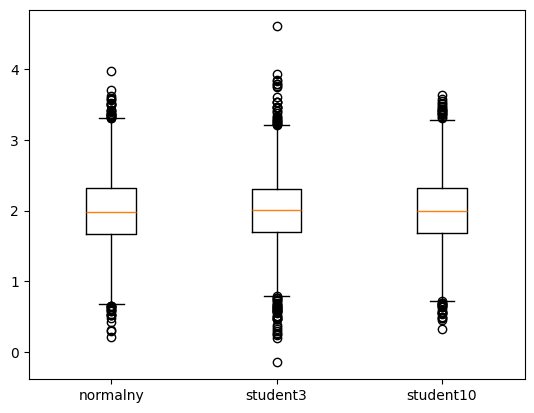

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


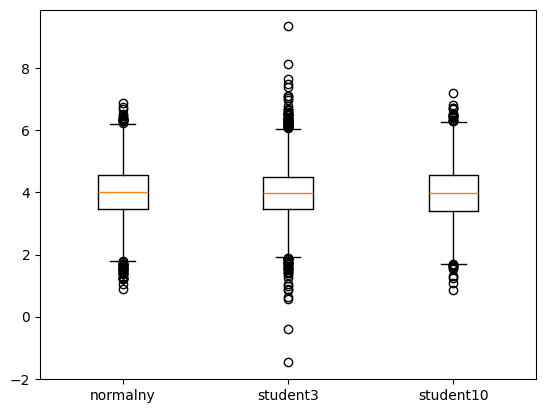

DLA N = 100
norm
Wariancja b0 = 0.12017418792859644, Obciazenie b0 = -0.0016172464834056655
Wariancja b1 = 0.36235164317951807, Obciazenie b1 = 0.003003380788859644
t3
Wariancja b0 = 0.11620629776593651, Obciazenie b0 = 0.0011200306465020127
Wariancja b1 = 0.3581677533277163, Obciazenie b1 = -0.0014753970857324106
t10
Wariancja b0 = 0.1172853918047244, Obciazenie b0 = -0.005663653330237883
Wariancja b1 = 0.357527513511795, Obciazenie b1 = 0.015161989235041418


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


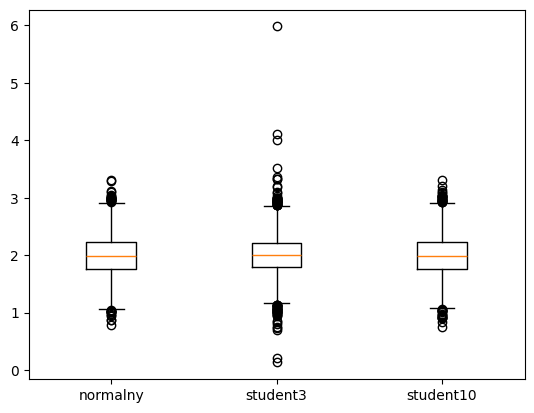

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


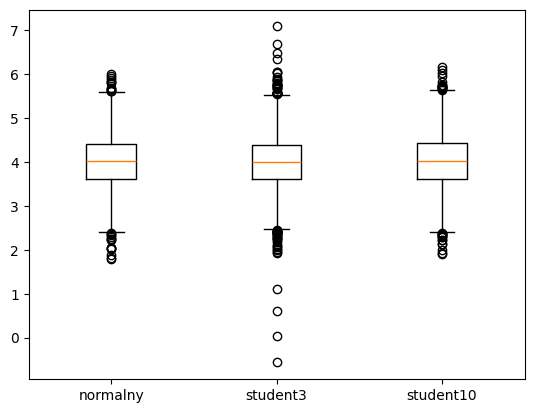

DLA N = 500
norm
Wariancja b0 = 0.02421824357755793, Obciazenie b0 = -6.351519891145685e-05
Wariancja b1 = 0.07181204103810339, Obciazenie b1 = 0.001607669615302676
t3
Wariancja b0 = 0.023592964753529982, Obciazenie b0 = -0.0032851989423898775
Wariancja b1 = 0.07008002885845074, Obciazenie b1 = 0.00442842440649116
t10
Wariancja b0 = 0.023668857093080913, Obciazenie b0 = 0.0030021630770913355
Wariancja b1 = 0.0722873820344352, Obciazenie b1 = -0.0020981837721061325


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:51: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])


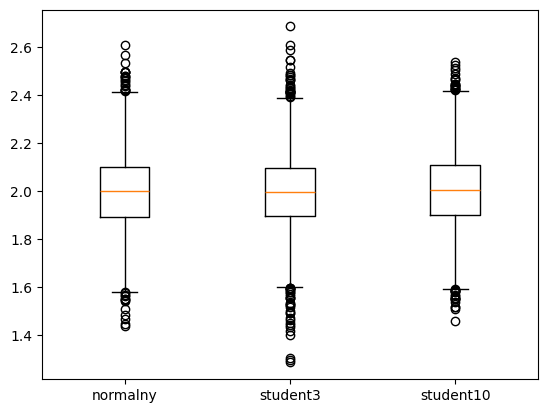

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18728\1023036386.py:54: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])


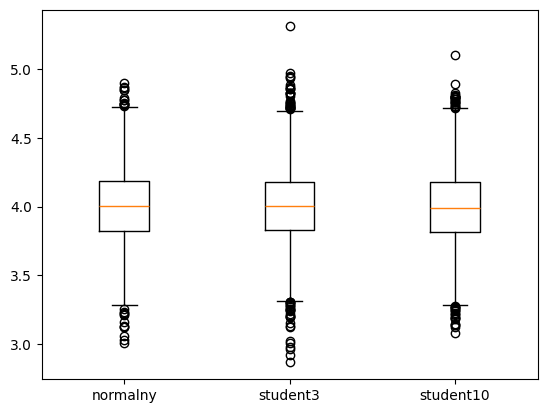

In [3]:
# zad 2

def model_regresji(xi,eps):
    return 2 + 4 * xi + eps

def eps_1(n):
    return np.random.normal(0,np.sqrt(3),n)

def eps_2(n):
    return np.random.standard_t(3,n)

def eps_3(n):
    return np.sqrt(2.4) * np.random.standard_t(10,n)

def monte_carlo_2(n,m,funkcja_eps):
    wektor_estymatorow_b0 = []
    wektor_estymatorow_b1 = []

    wektor_x = xi(n)

    for _ in range(m):
        wektor_eps = funkcja_eps(n)
        wektor_y = model_regresji(wektor_x,wektor_eps)

        b0_daszek, b1_daszek = estymatory_MNK_wspolczynnikow(wektor_x, wektor_y)

        wektor_estymatorow_b0.append(b0_daszek)
        wektor_estymatorow_b1.append(b1_daszek)

    return wektor_estymatorow_b0, wektor_estymatorow_b1

for n in [20,50,100,500]:
    print(f'DLA N = {n}')
    wektor_estymatorow_b0_norm, wektor_estymatorow_b1_norm = monte_carlo_2(n,5000,eps_1)
    wektor_estymatorow_b0_t3, wektor_estymatorow_b1_t3 = monte_carlo_2(n,5000,eps_2)
    wektor_estymatorow_b0_t10, wektor_estymatorow_b1_t10 = monte_carlo_2(n,5000,eps_3)

    print('norm')
    print(f'Wariancja b0 = {np.var(wektor_estymatorow_b0_norm)}, Obciazenie b0 = {np.mean(wektor_estymatorow_b0_norm) - 2}')
    print(f'Wariancja b1 = {np.var(wektor_estymatorow_b1_norm)}, Obciazenie b1 = {np.mean(wektor_estymatorow_b1_norm) - 4}')

    print('t3')
    print(f'Wariancja b0 = {np.var(wektor_estymatorow_b0_t3)}, Obciazenie b0 = {np.mean(wektor_estymatorow_b0_t3) - 2}')
    print(f'Wariancja b1 = {np.var(wektor_estymatorow_b1_t3)}, Obciazenie b1 = {np.mean(wektor_estymatorow_b1_t3) - 4}')

    print('t10')
    print(f'Wariancja b0 = {np.var(wektor_estymatorow_b0_t10)}, Obciazenie b0 = {np.mean(wektor_estymatorow_b0_t10) - 2}')
    print(f'Wariancja b1 = {np.var(wektor_estymatorow_b1_t10)}, Obciazenie b1 = {np.mean(wektor_estymatorow_b1_t10) - 4}')

    
    plt.boxplot([wektor_estymatorow_b0_norm, wektor_estymatorow_b0_t3,wektor_estymatorow_b0_t10], labels=['normalny', 'student3','student10'])
    plt.show()

    plt.boxplot([wektor_estymatorow_b1_norm, wektor_estymatorow_b1_t3,wektor_estymatorow_b1_t10], labels=['normalny', 'student3','student10'])
    plt.show()







Obciazenie empiryczne = 4.668540092689355e-05, Wariancja empiryczna = 0.0060782213292830045,srednia empiryczna = 3.000046685400927
Obciazenie teoretyczne = 0, Wariancja teoretyczna = 0.006018042090186379,srednia teoretyczna = 3


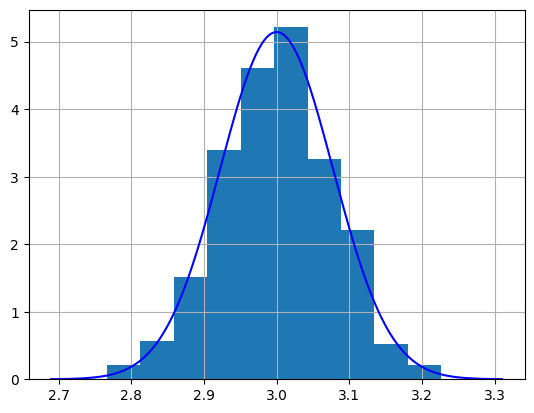

In [13]:
# zad 4
def model_4(x,eps):
    return 3 * x + eps

def epsilon_():
    return np.random.normal(0,1,500)

def estymator_b1(x,y):
    return np.sum(x * y)/ np.sum(x ** 2)

def monte_carlo_4():
    wektor_estymatorow = []
    for _ in range(500):
        x = xi(500)
        y = model_4(x,epsilon_())
        wektor_estymatorow.append(estymator_b1(x,y))
    return wektor_estymatorow

wektor_estymatorow_b1 = monte_carlo_4()

wariancja = np.var(wektor_estymatorow_b1,ddof=1)
srednia = np.mean(wektor_estymatorow_b1)
obciazenie = srednia - 3

x = xi(500)
print(f'Obciazenie empiryczne = {obciazenie}, Wariancja empiryczna = {wariancja},srednia empiryczna = {srednia}')
print(f'Obciazenie teoretyczne = {0}, Wariancja teoretyczna = {1/np.sum(x**2)},srednia teoretyczna = {3}')

mu = 3
sigma = np.sqrt(1/np.sum(x**2))
x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)

y = sc.norm.pdf(x, loc=mu, scale=sigma)

plt.plot(x,y,color='blue')
plt.hist(wektor_estymatorow_b1,density = True)
plt.grid()
plt.show()


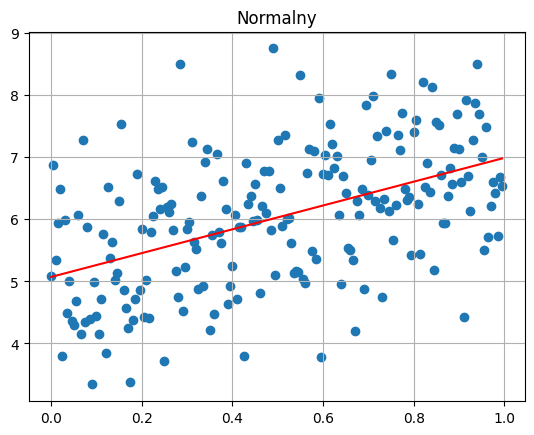

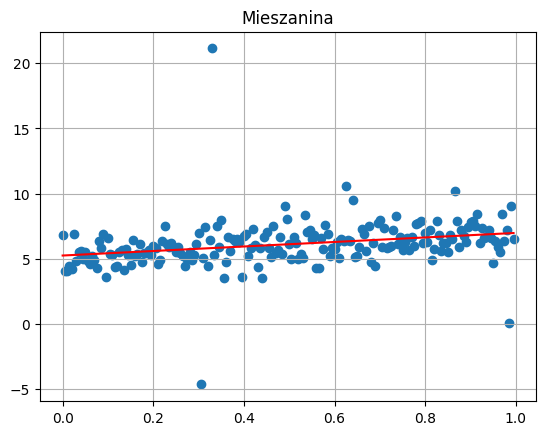

In [ ]:
# zad 3
# a
def xi(n):
    wektor = np.arange(n)/n
    return wektor

def eps_dziwny(n):
    n1 = np.random.normal(0,1,n)
    n25 = np.random.normal(0,5,n)
    dwupuntkowy = np.random.binomial(n=1, p=0.95, size=n)
    eps = dwupuntkowy * n1 + (1 - dwupuntkowy) * n25
    return eps

def eps_normalny(n):
    return np.random.normal(0,1,n)

def model_regresji(xi,eps):
    return 5 + 2 * xi + eps


# a
n = 200
x = xi(n)
y_normalny = model_regresji(x,eps_normalny(n))
y_dziwny = model_regresji(x,eps_dziwny(n))

estymator_b0_normalne = estymatory_MNK_wspolczynnikow(x,y_normalny)[0]
estymator_b1_normalne = estymatory_MNK_wspolczynnikow(x,y_normalny)[1]

estymator_b0_dziwne = estymatory_MNK_wspolczynnikow(x,y_dziwny)[0]
estymator_b1_dziwne = estymatory_MNK_wspolczynnikow(x,y_dziwny)[1]


plt.scatter(x,y_normalny)
plt.plot(x,estymator_b0_normalne + estymator_b1_normalne * x,c='red')
plt.title('Normalny')
plt.grid()
plt.show()

plt.scatter(x,y_dziwny)
plt.plot(x,estymator_b0_dziwne + estymator_b1_dziwne * x,c='red')
plt.title('Mieszanina')
plt.grid()
plt.show()

In [ ]:
# b

for n in [50,100,500]:
    for i in range(1000):
        x = xi(n)
        y_normalny = model_regresji(x,eps_normalny(n))
        y_dziwny = model_regresji(x,eps_dziwny(n))

        estymator_b0_normalne = estymatory_MNK_wspolczynnikow(x,y_normalny)[0]
        estymator_b1_normalne = estymatory_MNK_wspolczynnikow(x,y_normalny)[1]

        estymator_b0_dziwne = estymatory_MNK_wspolczynnikow(x,y_dziwny)[0]
        estymator_b1_dziwne = estymatory_MNK_wspolczynnikow(x,y_dziwny)[1]

        